# Entrega 2 — Estimación de ventas de videojuegos

**Autor:** Alex Porras Martinez  
**Empresa:** PixelBridge Games  
**Proyecto:** Análisis de ventas de videojuegos

Este cuaderno utiliza datos históricos de videojuegos para estimar las ventas mundiales de un posible lanzamiento. El trabajo sigue el objetivo de la primera entrega y combina un análisis sencillo de datos con dos modelos predictivos.

## 0. Executive summary — Resumen ejecutivo

1. **Pregunta:** ¿cuántas copias podría vender un videojuego según su género, plataforma y año de lanzamiento?
2. **Método:** he comparado un árbol de decisión y un bosque aleatorio con dos reglas sencillas de ventas históricas.
3. **Resultado:** el árbol elegido consigue un RMSE muy parecido al de la regla por género, pero comete más error medio (MAE).
4. **Decisión:** PixelBridge Games debería seguir usando las ventas habituales por género como primera referencia y probar el modelo solo como apoyo.
5. **Límite:** son datos antiguos, con juegos muy diferentes entre sí, por lo que no podemos garantizar las ventas futuras.

**Qué significa para el responsable:** la predicción sirve para comparar ideas, no para asegurar cuánto dinero se ganará. Si la regla sencilla es más fiable, se debe utilizar antes que un modelo complicado.

## 1. From the brief to an ML task — Qué queremos predecir

PixelBridge Games es una empresa ficticia que estudia qué videojuegos podría publicar. La decisión es **qué propuestas revisar primero**, según sus posibles ventas mundiales. Se mantiene el mismo objetivo de estimación de la primera entrega; no ha sido necesario cambiar el dato que queremos predecir.

| Pregunta | Decisión de este proyecto |
|---|---|
| Decisión empresarial | Comparar y ordenar propuestas de videojuegos |
| Tipo de tarea | **Regresión**: obtener una cantidad, no un sí/no |
| Dato a predecir | `Global_Sales` (millones de copias) |
| Qué representa cada predicción | Un juego publicado en una plataforma concreta |
| Cuándo se predice | Antes de publicar el videojuego |
| Horizonte | Ventas acumuladas que recoge el dataset; no hay un plazo fijo de meses |
| Datos que conocemos antes | Género, plataforma elegida y año previsto de lanzamiento |
| Regla actual para comparar | Consultar las ventas habituales del mismo género (supuesto del caso) |
| Medidas de error | MAE y RMSE, las dos en millones de copias |
| Utilidad | Comparar potencial comercial sin confundir ventas con beneficios |

**MAE** significa error absoluto medio: indica cuánto nos equivocamos normalmente. **RMSE** también mide el error, pero penaliza mucho los fallos grandes. 

**Qué significa para el responsable:** cada predicción será una estimación en millones de copias para una propuesta concreta. La empresa puede ordenar varias propuestas, pero también debe considerar los costes y otras cuestiones que no aparecen en estos datos.

## 2. Data and quality — Datos y limpieza

Utilizo el archivo `Video_Games.csv` de Kaggle, el mismo de la primera entrega. Tiene **16.719 filas y 16 columnas**. Un registro representa la combinación de un videojuego con una plataforma; no son ventas mensuales, y el año es el de lanzamiento.

Para evitar problemas, elimino las filas sin año, género, plataforma o ventas mundiales, y compruebo los duplicados. No elimino los juegos que vendieron muchísimo, porque podrían ser casos reales; sus cifras sí pueden provocar errores grandes. No se rellenan valores vacíos con cifras inventadas: las columnas usadas por el modelo quedan completas después de la limpieza. 

In [1]:
# 1. Importamos las bibliotecas necesarias.
from pathlib import Path
import pandas as pd
import plotly.express as px
import plotly
import joblib
import sklearn
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import GridSearchCV
from sklearn.inspection import permutation_importance

SEMILLA = 42

# 2. Buscamos el CSV en la carpeta del notebook o del repositorio.
archivo = Path('data/Video_Games.csv')
if not archivo.exists():
    archivo = Path('project/data/Video_Games.csv')
if not archivo.exists():
    raise FileNotFoundError('Coloca Video_Games.csv en project/data/ y abre esa carpeta en VS Code')

carpeta_proyecto = archivo.parent.parent
original = pd.read_csv(archivo)

# 3. Quitamos filas sin los datos imprescindibles.
sin_anio = original['Year_of_Release'].isna().sum()
sin_genero = original['Genre'].isna().sum()
duplicados = original.duplicated().sum()

datos = original.dropna(subset=['Year_of_Release', 'Genre', 'Platform', 'Global_Sales'])
datos = datos.drop_duplicates().copy()
datos['Year_of_Release'] = datos['Year_of_Release'].astype(int)
datos = datos.sort_values('Year_of_Release').reset_index(drop=True)

print('Filas originales:', len(original))
print('Sin año:', sin_anio, '| Sin género:', sin_genero)
print('Duplicados:', duplicados)
print('Filas eliminadas:', len(original) - len(datos))
print('Filas utilizadas:', len(datos))
print('Ventas máxima y mínima (millones):', datos['Global_Sales'].max(), datos['Global_Sales'].min())

Filas originales: 16719
Sin año: 269 | Sin género: 2
Duplicados: 0
Filas eliminadas: 271
Filas utilizadas: 16448
Ventas máxima y mínima (millones): 82.53 0.01


El resultado es **16.448 registros válidos**: se descartan **271** (269 sin año y otros 2 sin género), y no hay filas completamente duplicadas. El máximo de `Global_Sales` es **82,53 millones**; se mantiene porque no hay pruebas de que sea incorrecto. El archivo pesa menos de 50 MB y se carga usando una ruta relativa.

**Qué significa para el responsable:** las comparaciones se basan en registros con los datos principales completos. Los casos con ventas extraordinarias siguen presentes, pero tendremos cuidado al interpretar la precisión del modelo.

## 3. What the exploration showed — Qué muestran los datos

 Para los gráficos uso los juegos lanzados **hasta 2014**; los de 2015 en adelante quedan reservados para la prueba final. Se muestran cuatro gráficos: distribución de ventas, ventas habituales por género, porcentaje de Japón y comparación de plataformas dentro de los juegos de disparos.

El histograma se limita visualmente a 3 millones de copias para que se vean mejor los juegos con ventas pequeñas. **No se eliminan las ventas mayores del análisis.**

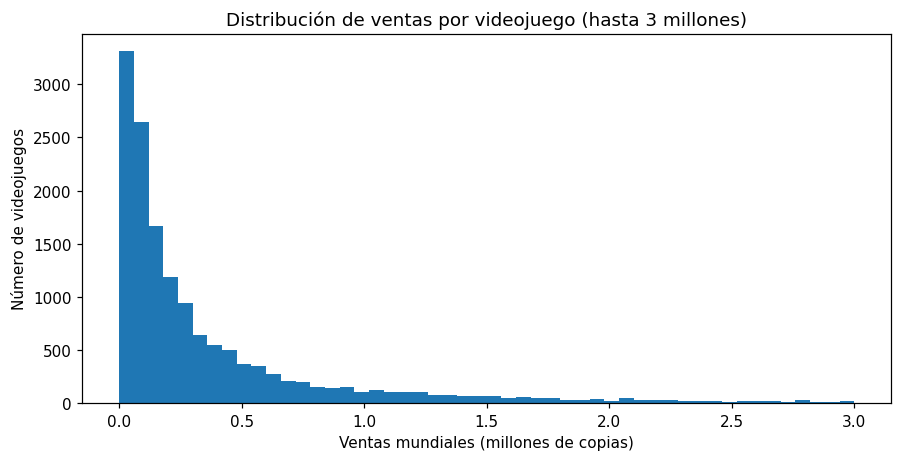

In [2]:
exploracion = datos[datos['Year_of_Release'] <= 2014].copy()

fig = px.histogram(exploracion, x='Global_Sales', nbins=50, range_x=[0, 3],
                   title='Distribución de ventas por videojuego (hasta 3 millones)')
fig.update_layout(xaxis_title='Ventas mundiales (millones de copias)',
                  yaxis_title='Número de videojuegos')
fig.show()

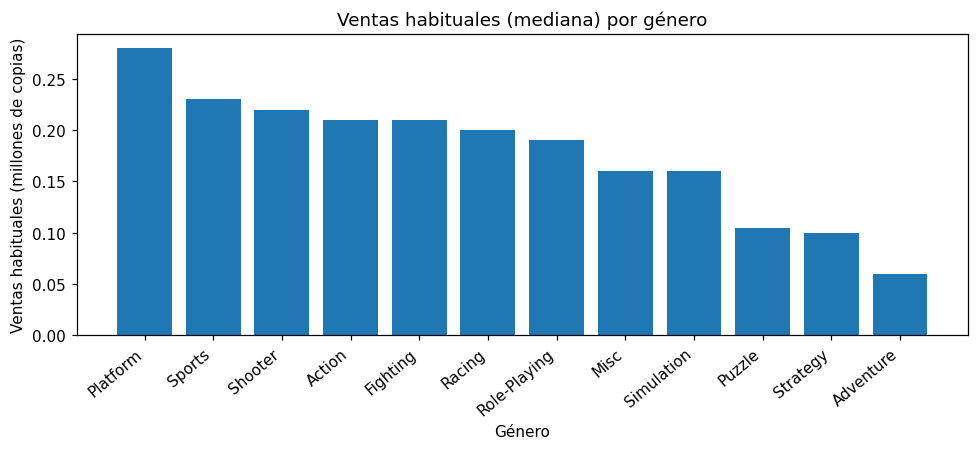

In [3]:
ventas_genero = exploracion.groupby('Genre', as_index=False).agg(
    mediana=('Global_Sales', 'median'), juegos=('Global_Sales', 'size'))
ventas_genero = ventas_genero.sort_values('mediana', ascending=False)

fig = px.bar(ventas_genero, x='Genre', y='mediana', hover_data=['juegos'],
             title='Ventas habituales (mediana) por género')
fig.update_layout(xaxis_title='Género',
                  yaxis_title='Ventas habituales (millones de copias)')
fig.show()

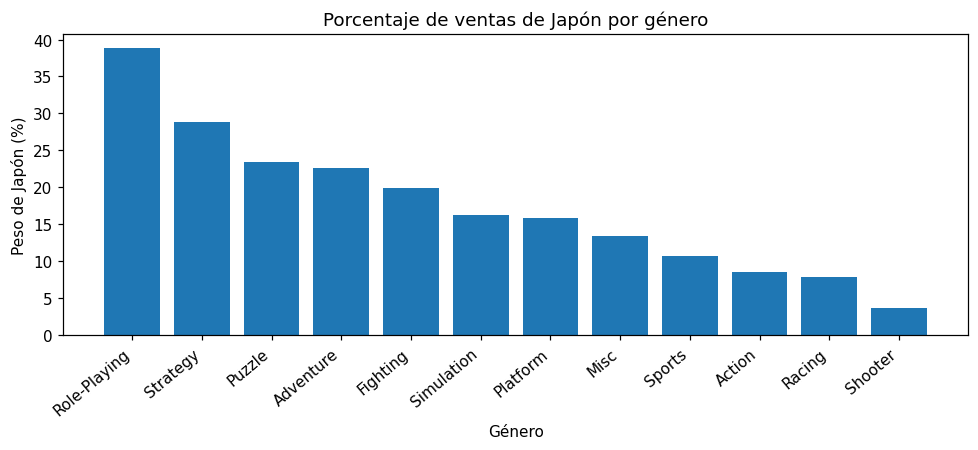

In [4]:
japon = exploracion.groupby('Genre', as_index=False)[['JP_Sales', 'Global_Sales']].sum()
japon['porcentaje_japon'] = 100 * japon['JP_Sales'] / japon['Global_Sales']

fig = px.bar(japon.sort_values('porcentaje_japon', ascending=False),
             x='Genre', y='porcentaje_japon',
             title='Porcentaje de ventas de Japón por género')
fig.update_layout(xaxis_title='Género', yaxis_title='Peso de Japón (%)')
fig.show()

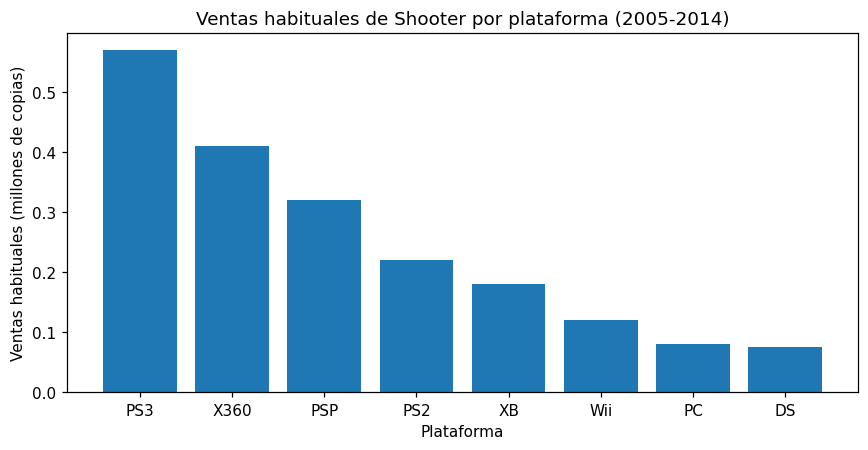

In [5]:
disparos = exploracion[(exploracion['Genre'] == 'Shooter') &
                         exploracion['Year_of_Release'].between(2005, 2014)]
plataformas = disparos.groupby('Platform', as_index=False).agg(
    mediana=('Global_Sales', 'median'), juegos=('Global_Sales', 'size'))
plataformas = plataformas[plataformas['juegos'] >= 30]

fig = px.bar(plataformas.sort_values('mediana', ascending=False),
             x='Platform', y='mediana', hover_data=['juegos'],
             title='Ventas habituales de Shooter por plataforma (2005-2014)')
fig.update_layout(xaxis_title='Plataforma',
                  yaxis_title='Ventas habituales (millones de copias)')
fig.show()

### Resultado de nuestras hipótesis

| Hipótesis del proyecto | Resultado | Datos observados |
|---|---|---|
| H1. Shooter suele vender más que la mediana general | **Apoyada** | Mediana de Shooter: **0,22 M**; general: **0,18 M** |
| H2. Los juegos de rol tienen mayor peso de Japón | **Apoyada** | Japón representa **38,9 %** de las ventas de rol, frente al **14,7 %** general |
| H3. El mismo género vende distinto según la plataforma | **Apoyada como relación** | En Shooter, 2005–2014: mediana de PS3 **0,57 M** (151 juegos), frente a PC **0,08 M** (112 juegos) |

Estas comparaciones no demuestran que el género o la plataforma *causen* las ventas. Por ejemplo, las plataformas también tienen públicos y épocas diferentes.

**Qué significa para el responsable:** el género y la plataforma aportan información para estudiar propuestas. Los resultados de Japón permiten entender mejor el mercado de rol, aunque no sean una entrada del modelo predictivo.

## 4. Features — Información que usa el modelo

Para que el modelo sea fácil de entender, utilizo solo tres columnas de entrada:

| Columna | Qué indica | Preparación | ¿Se sabe antes de publicar? |
|---|---|---|---|
| `Genre` | Tipo de videojuego | Se convierte en columnas de sí/no | Sí |
| `Platform` | Consola o plataforma | Se convierte en columnas de sí/no | Sí |
| `Year_of_Release` | Año de lanzamiento | Se utiliza como número | Sí, el año previsto |

La conversión de género y plataforma se llama **OneHotEncoder**. Por ejemplo, crea una columna que indica si un juego es de acción y otra si es de deportes. 

**Control de filtración de datos (*leakage*):** no utilizo `Global_Sales` ni `NA_Sales`, `EU_Sales`, `JP_Sales` y `Other_Sales` como entradas, porque esas ventas se conocen después. Tampoco utilizo las puntuaciones de los usuarios y críticos. El sistema para convertir las categorías se aprende solo con los datos de entrenamiento, dentro del pipeline.

In [6]:
# Las columnas con las que el modelo tendrá que trabajar.
COLUMNAS = ['Genre', 'Platform', 'Year_of_Release']

# Un pipeline prepara las columnas y después hace la predicción.
def crear_pipeline(modelo):
    preparacion = ColumnTransformer([
        ('categorias', OneHotEncoder(handle_unknown='ignore'), ['Genre', 'Platform'])
    ], remainder='passthrough')
    return Pipeline([
        ('preparar', preparacion),
        ('modelo', modelo)
    ])

print('Datos que pedirá el modelo:', COLUMNAS)

Datos que pedirá el modelo: ['Genre', 'Platform', 'Year_of_Release']


**Qué significa para el responsable:** para calcular una previsión bastará con conocer el género, la plataforma y el año previsto. El modelo no recibe información del futuro ni las ventas que intenta adivinar.

## 5. Split and baseline — Separación y reglas sencillas

Separo los registros por año porque queremos aprender de lanzamientos anteriores y comprobar qué habría pasado con juegos posteriores. Uso **hasta 2011 para entrenar**, **2012–2014 para comparar modelos** y **2015–2020 como prueba final**. Los cuatro registros posteriores a 2016 son muy pocos y no sirven para afirmar que conocemos bien el mercado actual.

Antes de los modelos pruebo dos reglas: predecir siempre la **mediana general** y predecir la **mediana del género**. La segunda representa una manera sencilla de trabajar de nuestro responsable ficticio. Las medianas solo se calculan con el periodo permitido.

In [7]:
train = datos[datos['Year_of_Release'] <= 2011].copy()
val = datos[datos['Year_of_Release'].between(2012, 2014)].copy()
test = datos[datos['Year_of_Release'] >= 2015].copy()

print('Entrenamiento:', len(train), 'juegos')
print('Validación:', len(val), 'juegos')
print('Prueba final:', len(test), 'juegos')

# Función para medir cuánto falla una predicción.
def medir(real, predicho):
    mae = mean_absolute_error(real, predicho)
    rmse = mean_squared_error(real, predicho) ** 0.5
    return round(mae, 3), round(rmse, 3)

mediana_general = train['Global_Sales'].median()
mediana_genero = train.groupby('Genre')['Global_Sales'].median()

pred_general = [mediana_general] * len(val)
pred_genero = val['Genre'].map(mediana_genero).fillna(mediana_general)

print('Regla mediana general (MAE, RMSE):', medir(val['Global_Sales'], pred_general))
print('Regla por género (MAE, RMSE):', medir(val['Global_Sales'], pred_genero))

Entrenamiento: 13558 juegos
Validación: 1778 juegos
Prueba final: 1112 juegos
Regla mediana general (MAE, RMSE): (0.527, 1.458)
Regla por género (MAE, RMSE): (0.517, 1.45)


**Qué significa para el responsable:** estas reglas permiten comprobar si merece la pena entrenar modelos. 

## 6. Candidate models — Dos modelos candidatos

Pruebo dos opciones que ofrece scikit-learn. El **árbol de decisión** divide los juegos en grupos según sus características y calcula una estimación. El **bosque aleatorio** utiliza varios árboles y combina sus respuestas. 

Los modelos utilizan el pipeline del apartado anterior. Esto significa que las categorías se convierten automáticamente en números durante el entrenamiento, sin preparar toda la base de datos por adelantado. He fijado `random_state=42` para que los resultados sean reproducibles.

In [8]:
arbol = crear_pipeline(DecisionTreeRegressor(
    max_depth=5, min_samples_leaf=25, random_state=SEMILLA))

bosque = crear_pipeline(RandomForestRegressor(
    n_estimators=40, max_depth=8, min_samples_leaf=10,
    random_state=SEMILLA, n_jobs=1))

# Entrenamos con el pasado y comparamos con los años 2012-2014.
arbol.fit(train[COLUMNAS], train['Global_Sales'])
bosque.fit(train[COLUMNAS], train['Global_Sales'])

resultados = pd.DataFrame([
    ['Mediana general', *medir(val['Global_Sales'], pred_general)],
    ['Mediana por género', *medir(val['Global_Sales'], pred_genero)],
    ['Árbol de decisión', *medir(val['Global_Sales'], arbol.predict(val[COLUMNAS]))],
    ['Bosque aleatorio', *medir(val['Global_Sales'], bosque.predict(val[COLUMNAS]))],
], columns=['Método', 'MAE (M)', 'RMSE (M)'])
display(resultados)

# El RMSE es casi igual entre ambos modelos: elegimos el árbol por ser más sencillo.
modelo_elegido = 'Árbol de decisión'
print('Modelo elegido:', modelo_elegido)

,Método,MAE (M),RMSE (M)
0,Mediana general,0.527,1.458
1,Mediana por género,0.517,1.450
2,Árbol de decisión,0.623,1.379
3,Bosque aleatorio,0.584,1.380


Modelo elegido: Árbol de decisión


En validación, el árbol obtiene aproximadamente **1,379 M de RMSE** y el bosque **1,380 M**; la diferencia es mínima. Elegimos el árbol porque es más fácil de explicar. Las reglas con medianas producen **menor MAE**, así que todavía no se puede decir que el modelo sea claramente mejor.

**Qué significa para el responsable:** hemos probado dos alternativas reales sin dar por hecho que la más complicada gana. Si queremos usar una predicción para decidir, también debemos comprobar cómo falla frente a una regla histórica sencilla.

## 7. Metric and cost of errors — Qué significan los fallos

La **MAE** indica el error habitual. Por ejemplo, una MAE de 0,35 millones equivale a equivocarse unas **350.000 copias de media**, sin importar si la predicción quedó por encima o por debajo. La **RMSE** da más importancia a los errores muy grandes; importa porque sobrestimar un éxito puede llevar a estudiar inversiones poco realistas.

Para esta primera evaluación utilizo el **RMSE como medida principal** al comparar los modelos, sin dejar de mostrar el MAE.  Revisamos los errores más grandes para entender en qué casos el modelo funciona peor.

In [9]:
revision = val[['Name', 'Genre', 'Platform', 'Global_Sales']].copy()
revision['Estimación (M)'] = arbol.predict(val[COLUMNAS])
revision['Error (M)'] = abs(revision['Global_Sales'] - revision['Estimación (M)'])

print('Los cinco errores más grandes en validación:')
display(revision.sort_values('Error (M)', ascending=False).head(5).round(3))

Los cinco errores más grandes en validación:


,Name,Genre,Platform,Global_Sales,Estimación (M),Error (M)
14212,Grand Theft Auto V,Action,PS3,21.04,0.800,20.240
14218,Grand Theft Auto V,Action,X360,16.27,0.671,15.599
14752,Pokemon X/Pokemon Y,Role-Playing,3DS,14.60,0.491,14.109
13617,Call of Duty: Black Ops II,Shooter,PS3,13.79,0.800,12.990
13618,Call of Duty: Black Ops II,Shooter,X360,13.67,1.371,12.299


**Qué significa para el responsable:** los errores grandes aparecen especialmente cuando un juego vende mucho más de lo habitual. No conviene utilizar las previsiones como una promesa de ventas ni decidir el presupuesto únicamente por la cifra que devuelve el modelo.

## 8. Validation and tuning — Comprobar y ajustar

Ahora reviso varias combinaciones sencillas para el árbol. `max_depth` limita cuánto puede dividirse el árbol y `min_samples_leaf` evita que aprenda grupos demasiado pequeños. Uso **GridSearchCV**, que prueba esas opciones automáticamente.

La comprobación es temporal: cada prueba se entrena con años anteriores y comprueba años posteriores. Solo entran registros **hasta 2014**. Después hacemos **una única evaluación final** con los juegos de 2015 en adelante, que no se han utilizado para escoger los parámetros.

In [10]:
anteriores = datos[datos['Year_of_Release'] <= 2014].reset_index(drop=True)

# Cada pareja indica: hasta qué año entrenamos / hasta qué año validamos.
periodos = [(2005, 2007), (2008, 2010), (2011, 2012), (2013, 2014)]
pliegues = []
for ultimo_entrenamiento, ultimo_validacion in periodos:
    filas_train = list(anteriores.index[anteriores['Year_of_Release'] <= ultimo_entrenamiento])
    filas_val = list(anteriores.index[
        anteriores['Year_of_Release'].between(ultimo_entrenamiento + 1, ultimo_validacion)])
    pliegues.append((filas_train, filas_val))

# Cuatro combinaciones: dos profundidades y dos tamaños de grupo.
opciones = {
    'modelo__max_depth': [4, 6],
    'modelo__min_samples_leaf': [10, 30]
}

busqueda = GridSearchCV(
    crear_pipeline(DecisionTreeRegressor(random_state=SEMILLA)),
    opciones, cv=pliegues, scoring='neg_root_mean_squared_error', n_jobs=1)
busqueda.fit(anteriores[COLUMNAS], anteriores['Global_Sales'])

modelo_final = busqueda.best_estimator_
print('Mejor combinación:', busqueda.best_params_)
print('RMSE medio de las validaciones:', round(-busqueda.best_score_, 3), 'millones')
display(pd.DataFrame(busqueda.cv_results_)[['params', 'mean_test_score']].round(3))

Mejor combinación: {'modelo__max_depth': 4, 'modelo__min_samples_leaf': 10}
RMSE medio de las validaciones: 1.546 millones


,params,mean_test_score
0,"{'modelo__max_depth': 4, 'modelo__min_samples_...",-1.546
1,"{'modelo__max_depth': 4, 'modelo__min_samples_...",-1.546
2,"{'modelo__max_depth': 6, 'modelo__min_samples_...",-1.558
3,"{'modelo__max_depth': 6, 'modelo__min_samples_...",-1.551


In [11]:
# Esta es la única evaluación sobre los juegos reservados para la prueba final.
real_test = test['Global_Sales']
pred_modelo = modelo_final.predict(test[COLUMNAS])

# Comparamos con las dos reglas, calculadas solamente con años anteriores a 2015.
mediana_anteriores = anteriores['Global_Sales'].median()
mediana_genero_anteriores = anteriores.groupby('Genre')['Global_Sales'].median()
pred_base = test['Genre'].map(mediana_genero_anteriores).fillna(mediana_anteriores)

comparacion_final = pd.DataFrame([
    ['Regla por género', *medir(real_test, pred_base)],
    ['Árbol ajustado', *medir(real_test, pred_modelo)],
], columns=['Método', 'MAE (M)', 'RMSE (M)'])
print('Resultados de la prueba final:')
display(comparacion_final)

Resultados de la prueba final:


,Método,MAE (M),RMSE (M)
0,Regla por género,0.348,0.951
1,Árbol ajustado,0.522,0.951


El RMSE final del árbol queda **prácticamente empatado** con el de la regla por género, mientras que su MAE es bastante mayor. Por tanto, **no hay una mejora suficiente** para recomendar que sustituya la regla habitual. Los resultados de las validaciones también varían entre periodos; el modelo se enfrenta a una industria que cambia con los años.

**Qué significa para el responsable:** hemos comprobado el modelo con juegos que no había visto antes. La conclusión útil no es que debamos adoptarlo sin más, sino que de momento debemos conservar la referencia por género y tratar el árbol como una prueba de apoyo.

## 9. Interpretation — Explicar las predicciones

Para entender el árbol, compruebo qué pasa si mezclamos al azar los valores de una columna al hacer las predicciones. Si el error aumenta, esa columna era útil para el modelo. Esto se llama **importancia por permutación**; no prueba que una característica cause más ventas.

 Así se puede comprobar que el modelo devuelve cifras, pero no acierta exactamente en todos los casos.

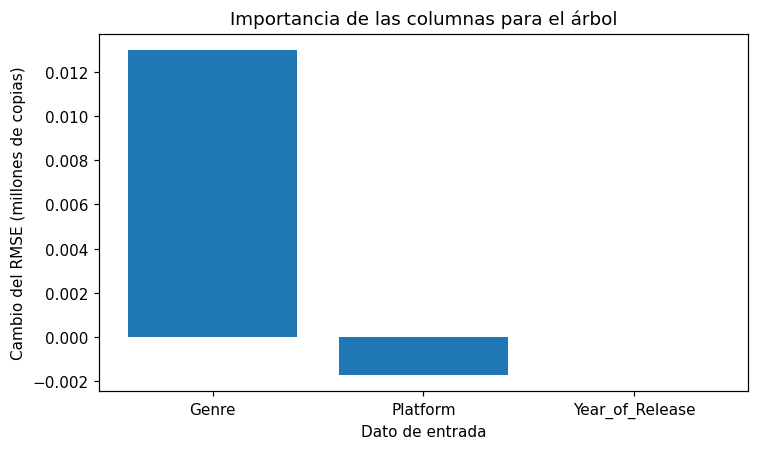

,Name,Genre,Platform,Year_of_Release,Global_Sales,Estimación (M),Error (M)
15772,The Legend of Legacy,Role-Playing,3DS,2015,0.25,0.522,0.272
15875,Etrian Mystery Dungeon,Role-Playing,3DS,2015,0.24,0.522,0.282
15392,Chaos;Child,Adventure,PSV,2015,0.05,0.124,0.074


In [12]:
importancia = permutation_importance(
    modelo_final, test[COLUMNAS], real_test,
    n_repeats=2, random_state=SEMILLA,
    scoring='neg_root_mean_squared_error', n_jobs=1)

importancias = pd.DataFrame({
    'Columna': COLUMNAS,
    'Aumento del RMSE (M)': importancia.importances_mean
})
fig = px.bar(importancias, x='Columna', y='Aumento del RMSE (M)',
             title='Importancia de las columnas para el árbol')
fig.update_layout(xaxis_title='Dato de entrada',
                  yaxis_title='Cambio del RMSE (millones de copias)')
fig.show()

# Tres ejemplos fijos para que siempre aparezcan los mismos juegos.
ejemplos = test.sample(n=3, random_state=SEMILLA).copy()
ejemplos['Estimación (M)'] = modelo_final.predict(ejemplos[COLUMNAS])
ejemplos['Error (M)'] = abs(ejemplos['Global_Sales'] - ejemplos['Estimación (M)'])
display(ejemplos[['Name', 'Genre', 'Platform', 'Year_of_Release',
                  'Global_Sales', 'Estimación (M)', 'Error (M)']].round(3))

**Qué significa para el responsable:** podemos ver qué datos ayudan al modelo y comprobar juegos concretos. La estimación sirve para orientar una comparación, pero un género con buenas ventas pasadas no garantiza que cada nuevo título también las consiga.

## 10. Fairness, ethics and risks — Errores, ética y riesgos

El CSV no necesita nombres de clientes, correos electrónicos ni otros datos personales: son registros comerciales de videojuegos y se utiliza según la licencia indicada por Kaggle (CC0). De todas formas, hay que revisar el origen de los datos y no inventar información que no existe.

Para comprobar si el modelo falla más en unos grupos que en otros, comparo la MAE por **género** en el conjunto de prueba. Muestro los géneros con al menos 25 juegos, para no sacar conclusiones fuertes a partir de unos pocos registros. 

El riesgo empresarial es sobrestimar ventas y dedicar recursos a una propuesta equivocada; también podríamos infravalorar un juego que luego triunfara. Por eso no se deben tomar decisiones automáticas a partir de estas cifras.

In [13]:
errores = test[['Genre', 'Global_Sales']].copy()
errores['Error absoluto (M)'] = abs(test['Global_Sales'].to_numpy() - pred_modelo)

por_genero = errores.groupby('Genre', as_index=False).agg(
    juegos=('Error absoluto (M)', 'size'),
    MAE=('Error absoluto (M)', 'mean'))
por_genero = por_genero[por_genero['juegos'] >= 25]
print('Error medio por género en la prueba final:')
display(por_genero.sort_values('MAE', ascending=False).round(3))

Error medio por género en la prueba final:


,Genre,juegos,MAE
8,Shooter,81,1.173
10,Sports,107,0.699
7,Role-Playing,134,0.553
4,Platform,28,0.532
6,Racing,42,0.489
0,Action,432,0.481
2,Fighting,37,0.476
9,Simulation,34,0.457
11,Strategy,29,0.419
3,Misc,71,0.413


**Qué significa para el responsable:** algunos tipos de videojuegos se predicen peor que otros. Antes de utilizar una estimación, conviene consultar el error habitual de ese género y revisar manualmente los casos con más riesgo.

## 11. Recommendation — Recomendación a la empresa

Recomiendo que **PixelBridge Games siga comparando primero las ventas habituales por género**, porque en la prueba final esa regla obtiene una MAE menor que el árbol. El árbol se puede guardar y utilizar en una prueba interna para aprender a comparar propuestas, pero **no justifica sustituir la regla actual**: su mejora en RMSE es prácticamente nula.

El indicador empresarial que sí podemos medir es el **error en millones de copias**. No sería correcto prometer más beneficios o un ahorro de dinero porque no tenemos costes ni precios. 

En el siguiente bloque se podrá conectar el modelo al panel de Streamlit y vigilar si sus errores mejoran o empeoran cuando entren datos nuevos. Antes de utilizarlo de verdad, la empresa debería conseguir datos de lanzamientos más recientes y volver a comprobarlo.

**Qué significa para el responsable:** por ahora las cifras son una ayuda para explorar posibilidades, no una herramienta que pueda decidir una inversión por sí sola. El trabajo ya deja preparado el modelo y una forma de medir si más adelante aporta valor.

## 12. Saving the model — Guardar el modelo

Guardo el árbol final como `model.joblib` usando **joblib**. El archivo incluye tanto la preparación de género y plataforma como el propio árbol: por eso podremos introducir después las mismas tres columnas sin preparar los números manualmente.

Para comprobar que se ha guardado bien, lo vuelvo a abrir y comparo una predicción antes y después. 

In [14]:
ruta_modelo = carpeta_proyecto / 'model.joblib'
joblib.dump(modelo_final, ruta_modelo)

modelo_abierto = joblib.load(ruta_modelo)
un_juego = test[COLUMNAS].iloc[[0]]
antes = modelo_final.predict(un_juego)[0]
despues = modelo_abierto.predict(un_juego)[0]

print('Modelo guardado en:', ruta_modelo)
print('Predicción antes de guardarlo:', round(antes, 3), 'millones')
print('Predicción después de abrirlo:', round(despues, 3), 'millones')
print('Coinciden:', abs(antes - despues) < 0.000001)
print('Python:', __import__('sys').version.split()[0])
print('Pandas:', pd.__version__)
print('Plotly:', plotly.__version__)
print('Scikit-learn:', sklearn.__version__)
print('Joblib:', joblib.__version__)

Modelo guardado en: model.joblib
Predicción antes de guardarlo: 0.522 millones
Predicción después de abrirlo: 0.522 millones
Coinciden: True
Python: 3.13.5
Pandas: 2.2.3
Plotly: 6.5.2
Scikit-learn: 1.8.0
Joblib: 1.5.3


**Qué significa para el responsable:** el modelo se puede volver a abrir sin entrenarlo otra vez. Lo tenemos preparado para una demostración en el panel, aunque sus resultados todavía no justifican su uso como única referencia comercial.

## 13. References — Referencias

- Naeem, I. M. (s. f.). *Video Game Sales Dataset Updated - Extra Feat* [Conjunto de datos]. Kaggle. https://www.kaggle.com/datasets/ibriiee/video-games-sales-dataset-2022-updated-extra-feat
- scikit-learn developers. (s. f.). *DecisionTreeRegressor*. scikit-learn. https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html
- scikit-learn developers. (s. f.). *RandomForestRegressor*. scikit-learn. https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html
- scikit-learn developers. (s. f.). *GridSearchCV*. scikit-learn. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
- Plotly Technologies Inc. (s. f.). *Plotly Express in Python*. Plotly. https://plotly.com/python/plotly-express/
- Creative Commons. (s. f.). *CC0 1.0 Universal*. https://creativecommons.org/publicdomain/zero/1.0/

**Qué significa para el responsable:** las fuentes permiten comprobar de dónde vienen los datos y las herramientas utilizadas. Esto facilita repetir el trabajo y revisar sus limitaciones.